# Watanabe and Flury - Capillary Bundle Model

In [ ]:
import sys
sys.path.append('../../')
import jax.numpy as jnp
import utils.petrophysic as petro
import matplotlib.pyplot as plt


#### Soil Type Definition

In [2]:
# Sandy soil parameters
# alpha = 14.5    # van Genuchten alpha [1/m]
# Ksat = 8.25e-5  # saturated hydraulic conductivity [m/s]
# N = 2.68        # van Genuchten N [-]
# theta_r = 0.045 # minimum volumetric water content [-]
# theta_s = 0.43  # maximum volumetric water content [-]

alpha = jnp.array([[3.36]])    # van Genuchten alpha [1/m]
print("alpha:", alpha.shape)
Ksat = jnp.array([[1.14e-4]])  # saturated hydraulic conductivity [m/s]
N = jnp.array([[7]])        # van Genuchten N [-]
theta_r = jnp.array([[0.015]]) # minimum volumetric water content [-]
theta_s = jnp.array([[0.36]])  # maximum volumetric water content [-]

alpha: (1, 1)


W0115 16:55:57.708247  916716 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.
W0115 16:55:57.709976  916604 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.


#### Calculate Capillary Distribution

In [3]:
T=-1
R, n_caps,dtheta, theta_steps = petro.capillary_distribution(alpha,N,theta_r,theta_s,sigma_w = 7.27e-2, rho_w = 1000, g = 9.81, nbins = 50)
print(theta_steps)
print(n_caps)
print(R)
d = petro.film_thickness(T, Tm =0, A=-1e-19 , rho_i=917, Lf=3.34e5)
r_GT = petro.critical_radius(T,Tm = 0)

theta_steps: [0.0219     0.0288     0.0357     0.0426     0.0495     0.0564
 0.0633     0.0702     0.0771     0.08400001 0.0909     0.0978
 0.10470001 0.1116     0.11850001 0.1254     0.1323     0.1392
 0.14610001 0.15300001 0.15990001 0.1668     0.1737     0.1806
 0.18750001 0.19440001 0.20130001 0.20820001 0.2151     0.22200002
 0.22890002 0.23580001 0.24270001 0.24960001 0.2565     0.26340002
 0.2703     0.2772     0.2841     0.291      0.2979     0.3048
 0.31170002 0.3186     0.3255     0.3324     0.3393     0.3462
 0.3531     0.36      ]
[[[0.0219     0.0288     0.0357     0.0426     0.0495     0.0564
   0.0633     0.0702     0.0771     0.08400001 0.0909     0.0978
   0.10470001 0.1116     0.11850001 0.1254     0.1323     0.1392
   0.14610001 0.15300001 0.15990001 0.1668     0.1737     0.1806
   0.18750001 0.19440001 0.20130001 0.20820001 0.2151     0.22200002
   0.22890002 0.23580001 0.24270001 0.24960001 0.2565     0.26340002
   0.2703     0.2772     0.2841     0.291      0.2979

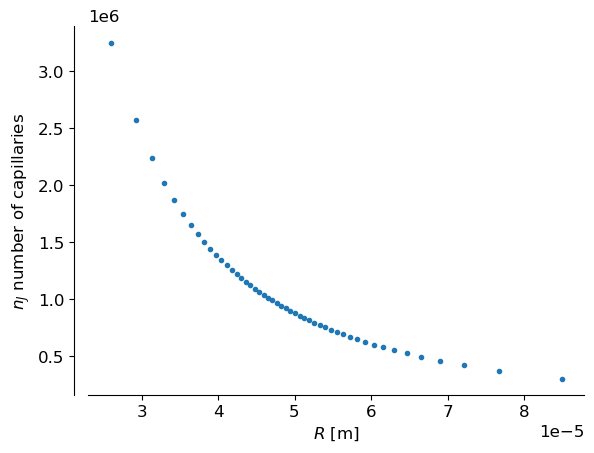

In [4]:
fig, ax = plt.subplots()
ax.spines[['top','right']].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax.set_xlabel(r"$R$ [m]")
ax.set_ylabel(r"$n_J$ number of capillaries")
ax.plot(R[0,0,:],n_caps[0,0,:],".")
r_i = jnp.where(R-d<r_GT,jnp.zeros_like(R),R-d)
# fig,ax = plt.subplots()
# ax.spines[['top','right']].set_visible(False)
# ax.spines['left'].set_position(('outward', 10))
# ax.set_xlabel(r"$R$ [m]")
# ax.set_ylabel(r"$r_i$")
# ax.semilogx(R,r_i,".")

In [5]:
theta_l, k_rel = petro.theta_l_k_rel_interp(R,n_caps,theta_steps,alpha,N,theta_r,theta_s)

ValueError: vmap got inconsistent sizes for array axes to be mapped:
  * most axes (4 of them) had size 1, e.g. axis 0 of argument alpha of type float32[1];
  * some axes (2 of them) had size 20000, e.g. axis 0 of argument h of type float32[20000]

## Hydrostatic Test Case

Text(0, 0.5, '$z$ [m]')

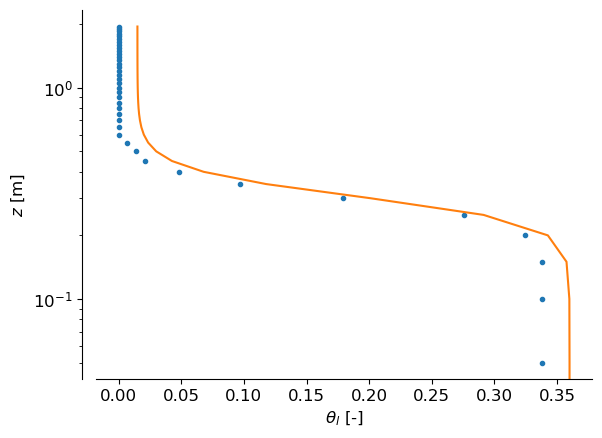

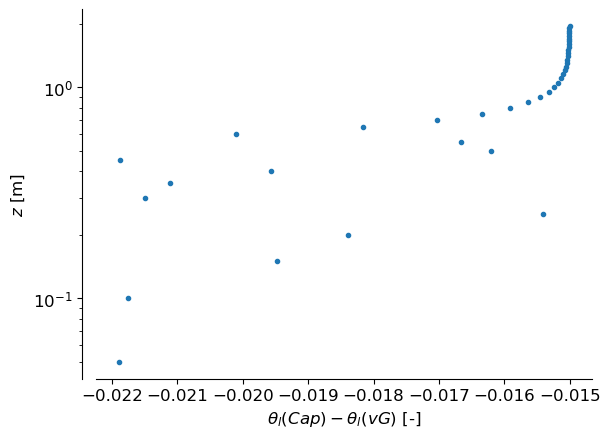

In [ ]:
z = jnp.arange(0,2,.05)
h_gw = 0
htot = jnp.ones(z.shape)*h_gw
h_c = z-htot
h_c = jnp.array([jnp.where(h_c<0,0,h_c)])
T=2*jnp.ones_like(h_c)
alpha = alpha*jnp.ones_like(z)
theta_r = theta_r*jnp.ones_like(z)
theta_s = theta_s*jnp.ones_like(z)
N = N*jnp.ones_like(z)
theta_l,_=petro.water_content_caps(h_c,T,R,n_caps,theta_steps,alpha,N,theta_r,theta_s)
theta_l_vG = petro.watercontent(h_c, alpha, N, theta_s, theta_r)
fig,ax = plt.subplots()
ax.semilogy(theta_l[0,:],z,".")
ax.semilogy(theta_l_vG[0,:],z)
ax.spines[['top','right']].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax.set_xlabel(r"$\theta_l$ [-]")
ax.set_ylabel(r"$z$ [m]")

fig,ax = plt.subplots()
ax.semilogy(theta_l[0,:]-theta_l_vG[0,:],z,".")
ax.spines[['top','right']].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax.set_xlabel(r"$\theta_l(Cap)-\theta_l(vG)$ [-]")
ax.set_ylabel(r"$z$ [m]")

Text(0, 0.5, '$K$ [m/s]')

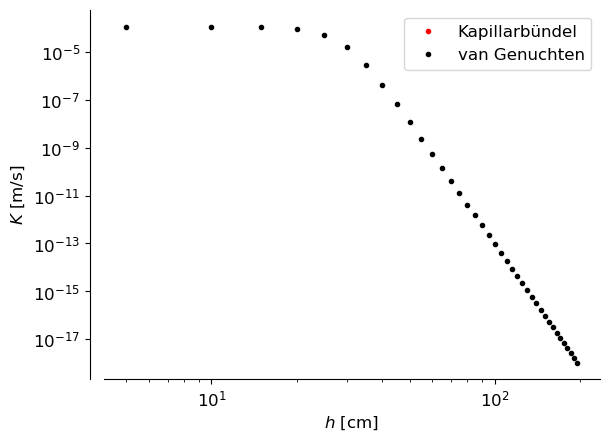

In [ ]:
S_e=petro.effsat(h_c, alpha, N)
krel_vG = petro.relperm(S_e,N)
Ku, k_rel, K_s_bundle = petro.K_u_caps(h_c,T,R,n_caps,theta_steps,alpha,N,theta_r,theta_s)
fig,ax = plt.subplots()
ax.loglog(h_c[0,:]*100,k_rel[0,:]*Ksat[0,0],".r", label="Kapillarbündel")
ax.loglog(h_c[0,:]*100,krel_vG[0,:]*Ksat[0,0],".k", label="van Genuchten")
ax.legend()
ax.spines[['top','right']].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax.set_xlabel(r"$h$ [cm]")
ax.set_ylabel(r"$K$ [m/s]")

In [ ]:
ku,krel,ksat_bundle = petro.K_u_caps(jnp.array([[20]]),jnp.array([[20]]),R,n_caps,theta_steps,alpha,N,theta_r,theta_s)

ValueError: vmap got inconsistent sizes for array axes to be mapped:
  * most axes (4 of them) had size 40, e.g. axis 0 of argument alpha of type float32[40];
  * some axes (2 of them) had size 1, e.g. axis 0 of argument h of type int32[1]

In [ ]:
 
# A=-1e-19 
# rho_i=917 
# Lf=3.34e5 
# omega_ls=2.9e-2
# xi=1
# rho_w=1000
# g=9.81
# eta_0=9.62e-7
# c=2046
# eta = eta_0*jnp.exp(c/(21.5+273.15))
# print(eta)    
# print(xi*rho_w*g*jnp.pi/(8*eta)*jnp.sum(n_caps*R**4))